# 1

### Nota: 9.63

En este proyecto, queremos que te embarques en la creación de un pipeline completo de preparación de datos utilizando el reconocido dataset del Titanic, disponible en Kaggle. Este ejercicio práctico está diseñado para que desarrolles y afiances las habilidades esenciales en la manipulación y limpieza de datos, competencias fundamentales para cualquier profesional en el campo de machine learning.

In [322]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

data_folder = "../media/1_lab3/1/"
data_file = "dataset.csv"
seed = 1234

Cargamos los datos.

In [323]:
df = pd.read_csv(data_folder + data_file)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Hay una columna índice, vamos a indicarlo a pandas. Además está la columna nombre, y ticket, que no aportan nada al modelo, por lo que se eliminan.

In [324]:
df = df.set_index("PassengerId")
df = df.drop(columns = ["Name", "Ticket"])
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
PassengerId,,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,NaN,S
2,1,1,female,38.0,1,0,71.2833,C85,C
3,1,3,female,26.0,0,0,7.9250,NaN,S
4,1,1,female,35.0,1,0,53.1000,C123,S
5,0,3,male,35.0,0,0,8.0500,NaN,S


In [325]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     204 non-null    str    
 8   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 62.8 KB


### Limpieza nulos

Veamos las columnas que tienen valores nulos.

In [326]:
round(df.isna().mean(), 3)

Survived    0.000
Pclass      0.000
Sex         0.000
Age         0.199
SibSp       0.000
Parch       0.000
Fare        0.000
Cabin       0.771
Embarked    0.002
dtype: float64

In [327]:
df.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Cabin       687
Embarked      2
dtype: int64

Hay algunas variables que presentan valores nulos:

- Un 77% de los datos no tienen la variable de cabina, por lo que sería sensato eliminar esta variable, pues no aporta casi información

- Un 0,2% (2 valores) no tienen la variable *Embarked*, entonces eliminaremos esos dos registros.

- El 20% no tiene anotado la edad, decidimos entonces llenar esos valores nulos con la mediana de la edad.

In [328]:
df = df.drop(columns = "Cabin")
indexes = df[df.Embarked.isna() == True].index
df = df.drop(index = indexes)
df.fillna({"Age": df.Age.median()}, inplace = True)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
PassengerId,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,S
2,1,1,female,38.0,1,0,71.2833,C
3,1,3,female,26.0,0,0,7.9250,S
4,1,1,female,35.0,1,0,53.1000,S
5,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
887,0,2,male,27.0,0,0,13.0000,S
888,1,1,female,19.0,0,0,30.0000,S
889,0,3,female,28.0,1,2,23.4500,S


In [329]:
df.info()

<class 'pandas.DataFrame'>
Index: 889 entries, 1 to 891
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  889 non-null    int64  
 1   Pclass    889 non-null    int64  
 2   Sex       889 non-null    str    
 3   Age       889 non-null    float64
 4   SibSp     889 non-null    int64  
 5   Parch     889 non-null    int64  
 6   Fare      889 non-null    float64
 7   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 62.5 KB


### Transformación de datos

Vamos a procesar las variables categóricas mediante one hot encoding, pues al tener dos variables categóricas, con solo dos categorías una, y tres otra, el aumento de columnas (3) es asumible.

In [330]:
df = pd.get_dummies(df).astype(int)

In [331]:
df.info()

<class 'pandas.DataFrame'>
Index: 889 entries, 1 to 891
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Survived    889 non-null    int64
 1   Pclass      889 non-null    int64
 2   Age         889 non-null    int64
 3   SibSp       889 non-null    int64
 4   Parch       889 non-null    int64
 5   Fare        889 non-null    int64
 6   Sex_female  889 non-null    int64
 7   Sex_male    889 non-null    int64
 8   Embarked_C  889 non-null    int64
 9   Embarked_Q  889 non-null    int64
 10  Embarked_S  889 non-null    int64
dtypes: int64(11)
memory usage: 83.3 KB


Ahora veamos si es necesario estandarizar, para tener una escala adecuada.

In [332]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Survived,889.0,0.382452,0.486260,0.0,0.0,0.0,1.0,1.0
Pclass,889.0,2.311586,0.834700,1.0,2.0,3.0,3.0,3.0
Age,889.0,29.299213,12.993433,0.0,22.0,28.0,35.0,80.0
SibSp,889.0,0.524184,1.103705,0.0,0.0,0.0,1.0,8.0
Parch,889.0,0.382452,0.806761,0.0,0.0,0.0,0.0,6.0
Fare,889.0,31.677165,49.706915,0.0,7.0,14.0,31.0,512.0
Sex_female,889.0,0.350956,0.477538,0.0,0.0,0.0,1.0,1.0
Sex_male,889.0,0.649044,0.477538,0.0,0.0,1.0,1.0,1.0
Embarked_C,889.0,0.188976,0.391710,0.0,0.0,0.0,0.0,1.0
Embarked_Q,889.0,0.086614,0.281427,0.0,0.0,0.0,0.0,1.0


Vamos a estandarizar las columnas *Age* y *Fare*, pues tienen valores promedios alejados al resto de las columnas.

In [333]:
standarize = lambda x: (x - x.mean()) / x.std()
df["Age"] = standarize(df["Age"])
df["Fare"] = standarize(df["Fare"])

In [334]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Survived,889.0,3.824522e-01,0.486260,0.000000,0.000000,0.000000,1.000000,1.000000
Pclass,889.0,2.311586e+00,0.834700,1.000000,2.000000,3.000000,3.000000,3.000000
Age,889.0,2.397782e-17,1.000000,-2.254925,-0.561762,-0.099990,0.438744,3.902032
SibSp,889.0,5.241845e-01,1.103705,0.000000,0.000000,0.000000,1.000000,8.000000
Parch,889.0,3.824522e-01,0.806761,0.000000,0.000000,0.000000,0.000000,6.000000
Fare,889.0,2.197967e-17,1.000000,-0.637279,-0.496453,-0.355628,-0.013623,9.663099
Sex_female,889.0,3.509561e-01,0.477538,0.000000,0.000000,0.000000,1.000000,1.000000
Sex_male,889.0,6.490439e-01,0.477538,0.000000,0.000000,1.000000,1.000000,1.000000
Embarked_C,889.0,1.889764e-01,0.391710,0.000000,0.000000,0.000000,0.000000,1.000000
Embarked_Q,889.0,8.661417e-02,0.281427,0.000000,0.000000,0.000000,0.000000,1.000000


In [335]:
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,
1,0,3,-0.561762,1,0,-0.496453,0,1,0,0,1
2,1,1,0.669630,1,0,0.791094,1,0,1,0,0
3,1,3,-0.253914,0,0,-0.496453,1,0,0,0,1
4,1,1,0.438744,1,0,0.428971,1,0,0,0,1
5,0,3,0.438744,0,0,-0.476335,0,1,0,0,1


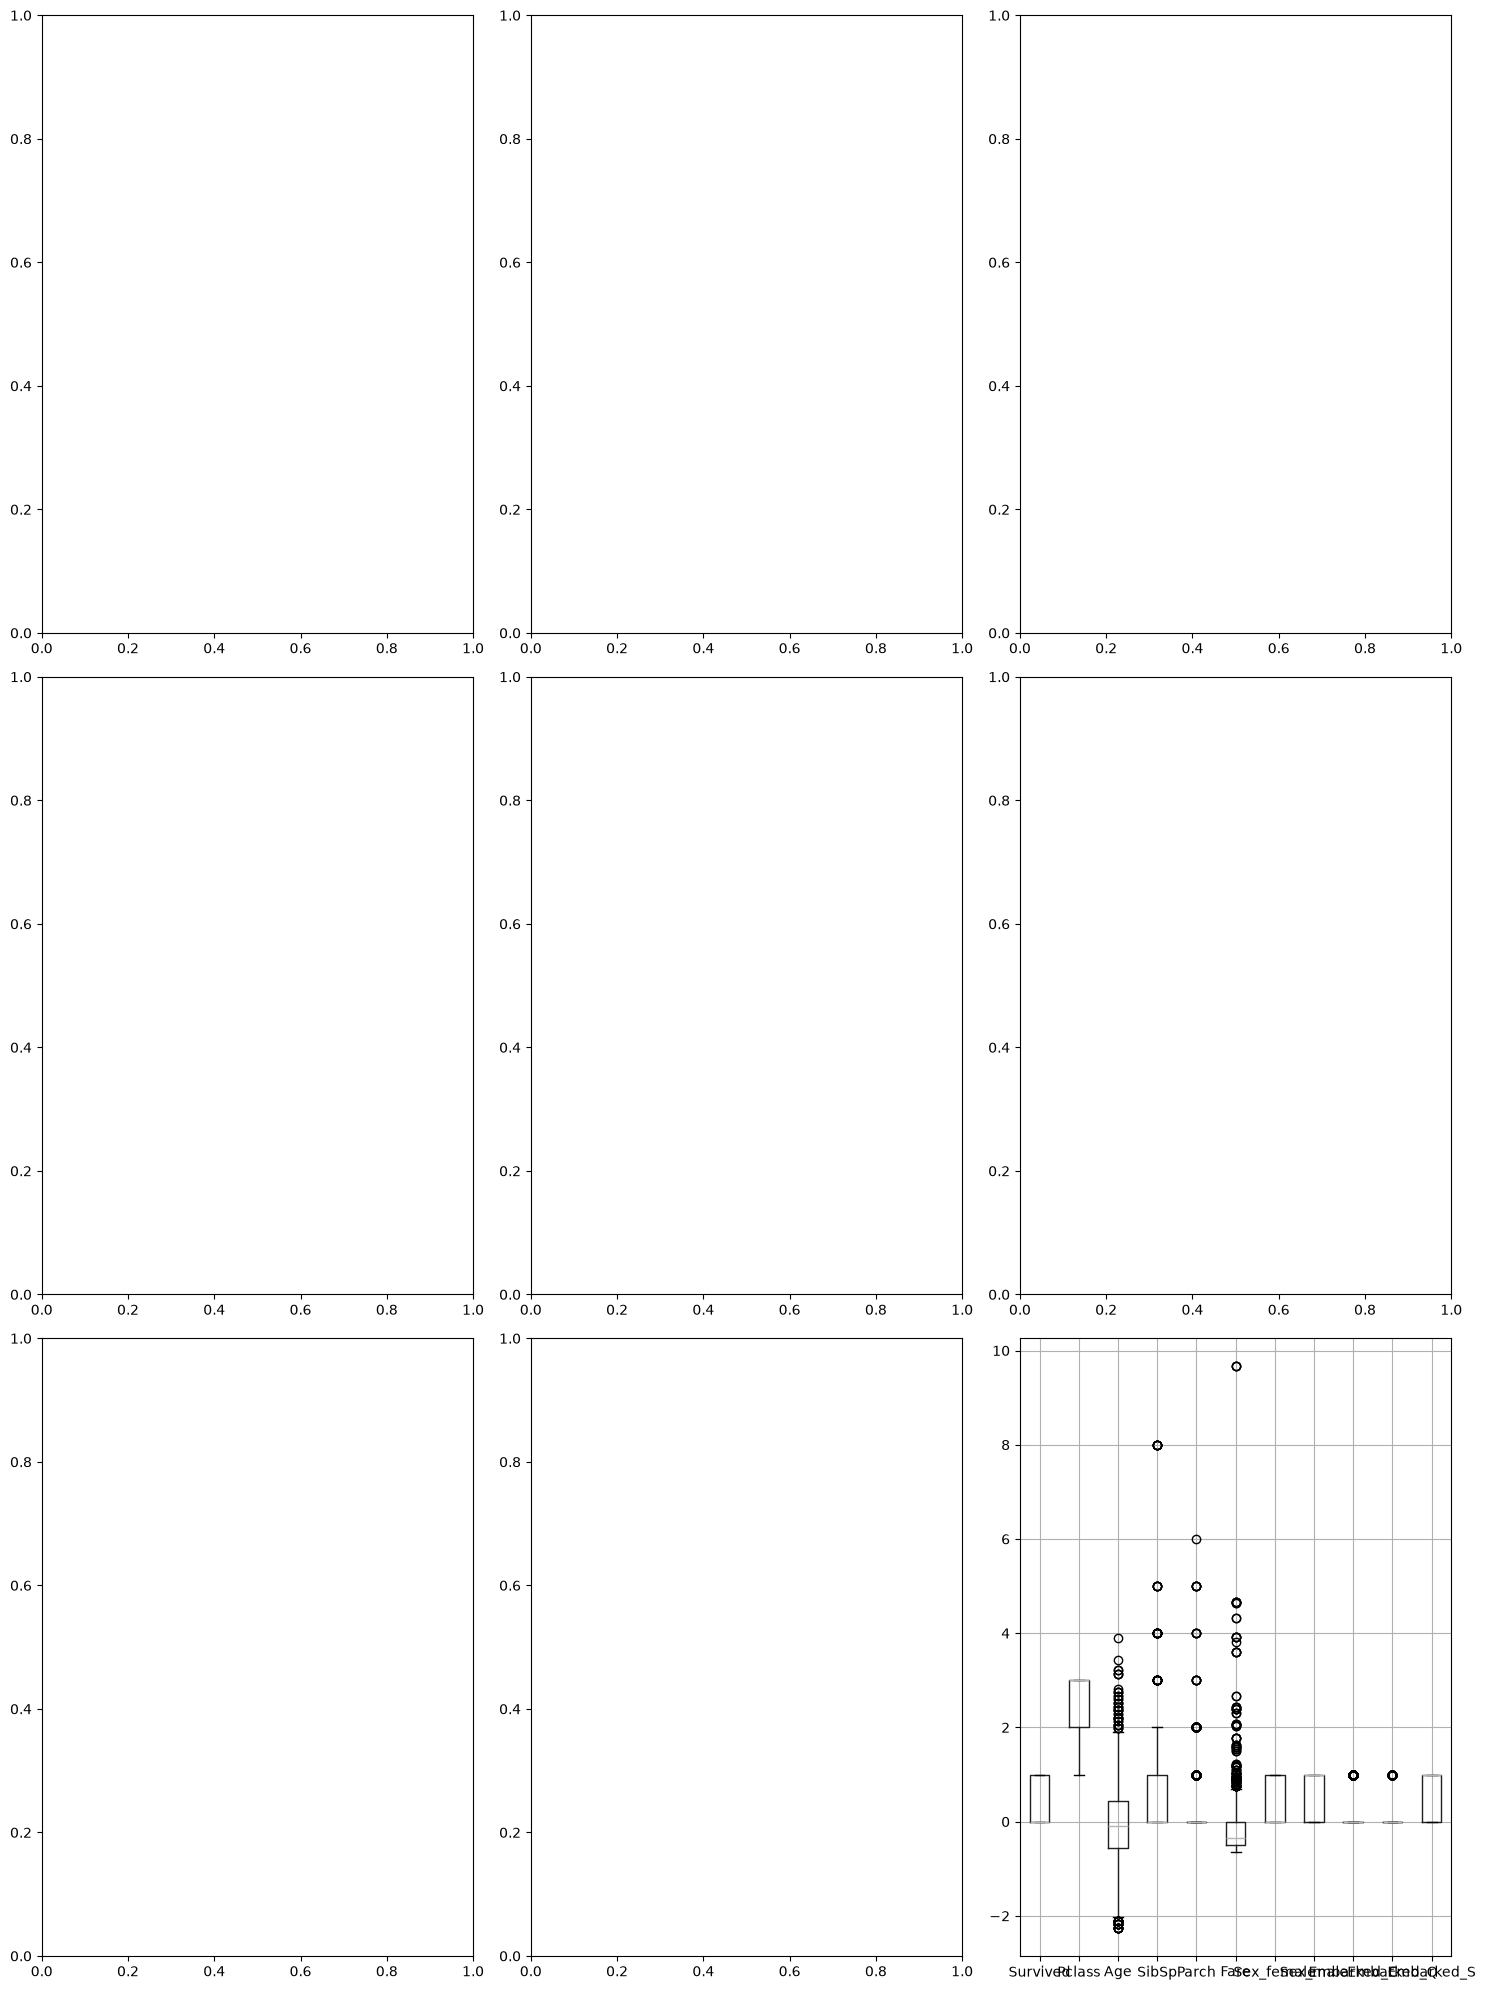

In [336]:
df.boxplot()
plt.tight_layout()
plt.show()

Guardamos el dataset.

In [337]:
df.to_csv(data_folder + "dataset_cleaned.csv")

# 2

### Nota: 8.4

Desarrolla un proyecto en Python utilizando Visual Studio Code para preparar y transformar datos del conjunto de calidad del vino. Deberás detectar y corregir valores anómalos con Pandas y Seaborn, aplicar técnicas de escalado con Scikit-learn, y documentar todo el proceso con visualizaciones que demuestren la efectividad de tus estrategias de preparación de datos.

In [338]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk

data_folder = "../media/1_lab3/2/"
data_file = "dataset.csv"
seed = 1234

Cargamos los datos.

In [339]:
df = pd.read_csv(data_folder + data_file, sep = ";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [340]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [341]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


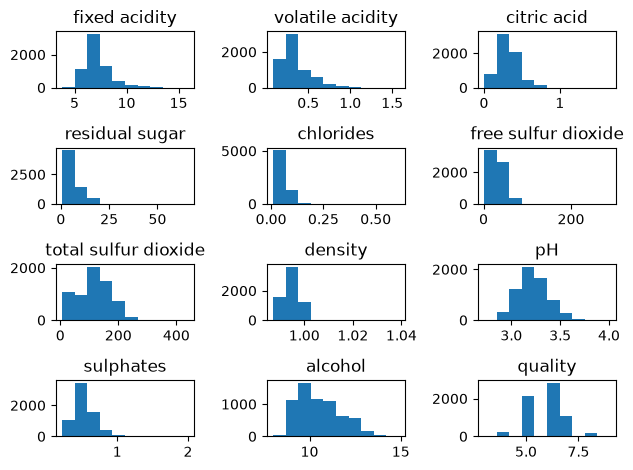

In [342]:
df.hist(grid = False)
plt.tight_layout()
plt.show()

Vemos que lsa categorías entre sí tienen escalas distintas, y algunas sesgadas, lo cual puede complicar el entrenamiento del modelo.

Hagamos un boxplots para cada columna (sin tener en cuenta *wine_type* que es categórico)

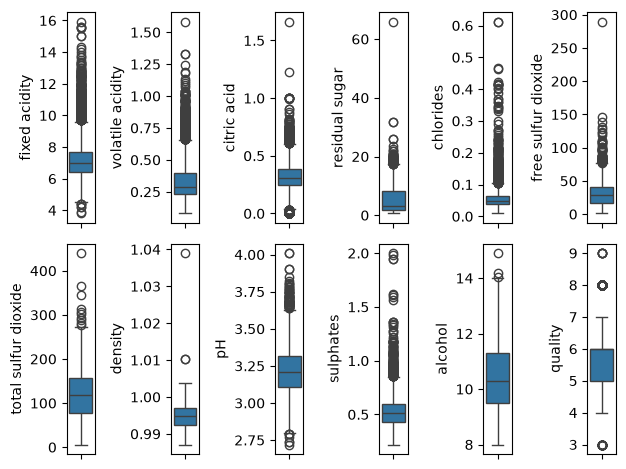

In [343]:
fig, ax = plt.subplots(nrows = 2, ncols = 6)
axes = ax.flatten()
for i, cat in enumerate(df.columns[:-1]):
    sns.boxplot(data = df, y = cat, ax = axes[i])

plt.tight_layout()
plt.show()

Vamos a calcular el IQR tanto superior como inferior de cada uno (Asegurándonos de cubrir el caso de la columna *quality* cuyo dtype es int64)

In [344]:
IQR = lambda x: x.quantile(0.75) - x.quantile(0.25) 
iqr_inf = lambda x: x.quantile(0.25) - 1.5 * IQR(x)
iqr_sup = lambda x: x.quantile(0.75) + 1.5 * IQR(x)

Primero veamos el porcentaje de outliers en cada variable (Como *quality* es la variable objetivo, no se le aplica ningún cambio).

In [345]:
for col in df.columns[:-2]:
    print(f"{col}: {round((len(df.loc[df[col] >= iqr_sup(df[col])]) + len(df.loc[df[col] <= iqr_inf(df[col])]))/ len(df) * 100, 2)}%")
    print(f"Límite inferior y superior: {iqr_inf(df[col])}, {iqr_sup(df[col])}")

fixed acidity: 5.49%
Límite inferior y superior: 4.450000000000001, 9.65
volatile acidity: 5.96%
Límite inferior y superior: -0.024999999999999994, 0.655
citric acid: 7.83%
Límite inferior y superior: 0.03999999999999998, 0.6000000000000001
residual sugar: 1.82%
Límite inferior y superior: -7.6499999999999995, 17.549999999999997
chlorides: 4.4%
Límite inferior y superior: -0.002500000000000009, 0.10550000000000001
free sulfur dioxide: 1.03%
Límite inferior y superior: -19.0, 77.0
total sulfur dioxide: 0.15%
Límite inferior y superior: -41.5, 274.5
density: 0.05%
Límite inferior y superior: 0.9853649999999999, 1.003965
pH: 1.12%
Límite inferior y superior: 2.795, 3.635
sulphates: 2.94%
Límite inferior y superior: 0.175, 0.855
alcohol: 0.05%
Límite inferior y superior: 6.799999999999999, 14.000000000000002


En ningún caso (quizás en *citric acid*) hay un número de outliers significativo, por lo que podemos aplicar el método y sustituir esos valores por el extremo más cercano.

Para cada columna, si el valor es superior a iqr_sup, se le asigna el valor iqr_sup, lo mismo si es inferior a iqr_inf.

In [346]:
for column in df.columns[:-2]:
    df.loc[df[column] >= iqr_sup(df[column]), column] = iqr_sup(df[column])
    df.loc[df[column] <= iqr_inf(df[column]), column] = iqr_inf(df[column])

In [347]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.142173,1.066080,4.45000,6.40000,7.00000,7.70000,9.650000
volatile acidity,6497.0,0.332612,0.144376,0.08000,0.23000,0.29000,0.40000,0.655000
citric acid,6497.0,0.316180,0.131856,0.04000,0.25000,0.31000,0.39000,0.600000
residual sugar,6497.0,5.407727,4.613702,0.60000,1.80000,3.00000,8.10000,17.550000
chlorides,6497.0,0.053230,0.021289,0.00900,0.03800,0.04700,0.06500,0.105500
free sulfur dioxide,6497.0,30.339541,16.904806,1.00000,17.00000,29.00000,41.00000,77.000000
total sulfur dioxide,6497.0,115.671926,56.256191,6.00000,77.00000,118.00000,156.00000,274.500000
density,6497.0,0.994689,0.002942,0.98711,0.99234,0.99489,0.99699,1.003965
pH,6497.0,3.217638,0.157901,2.79500,3.11000,3.21000,3.32000,3.635000
sulphates,6497.0,0.526667,0.131196,0.22000,0.43000,0.51000,0.60000,0.855000


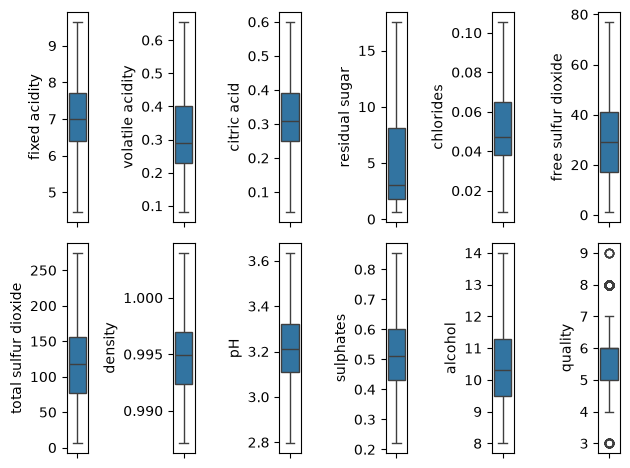

In [348]:
fig, ax = plt.subplots(nrows = 2, ncols = 6)
axes = ax.flatten()
for i, cat in enumerate(df.columns[:-1]):
    sns.boxplot(data = df, y = cat, ax = axes[i])

plt.tight_layout()
plt.show()

Al sustituir los outliers por los extremos del IQR, ya no aparecen.

### Escalado de datos

Vamos a escalar las columnas numéricas. Veamos la división entre la media y la diferencia de las distintas columnas para ver cuanto difieren.

In [349]:
abs(df.describe().T["mean"] / df.describe().T["50%"])

fixed acidity           1.020310
volatile acidity        1.146938
citric acid             1.019935
residual sugar          1.802576
chlorides               1.132549
free sulfur dioxide     1.046191
total sulfur dioxide    0.980271
density                 0.999798
pH                      1.002379
sulphates               1.032680
alcohol                 1.018604
quality                 0.969730
dtype: float64

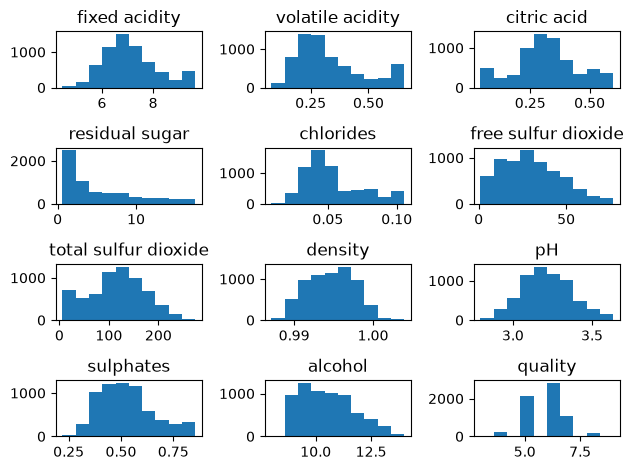

In [350]:
df.hist(grid = False);
plt.tight_layout()
plt.show()

Las columnas más sesgadas son:

- volatile acidity
- residual sugar
- chlorides
- sulphates

Es por eso que estas columnas las normalizamos, y el resto las estandarizamos. Esto se debe a que la normalización cambia el rango (no el sesgo de la distribución), lo que facilita al modelo el entrenamiento.

En cambio, la estandarización transforma la distribución a una de media 0 y desviación estándar 1, como se podrá comprobar después.

In [351]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

minmax = MinMaxScaler()
standard = StandardScaler()

minmax_cols = ["volatile acidity", "residual sugar", "chlorides", "sulphates"]

df_es = df.copy()
for col in df.columns[:-2]:
    if col in minmax_cols:
        df_es[col] = minmax.fit_transform(df[[col]])
    else:
        df_es[col] = standard.fit_transform(df[[col]])

Viendo las estadísticas de las columnas escaladas, comprobamos que o bien están normalizadas o estandarizadas.

In [352]:
df_es.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,5.249508e-16,1.000077,-2.525495,-0.696224,-0.133371,0.523290,2.352562
volatile acidity,6497.0,4.393252e-01,0.251088,0.000000,0.260870,0.365217,0.556522,1.000000
citric acid,6497.0,-2.406024e-16,1.000077,-2.094714,-0.501947,-0.046871,0.559897,2.152664
residual sugar,6497.0,2.836417e-01,0.272195,0.000000,0.070796,0.141593,0.442478,1.000000
chlorides,6497.0,4.583399e-01,0.220610,0.000000,0.300518,0.393782,0.580311,1.000000
free sulfur dioxide,6497.0,6.999344e-17,1.000077,-1.735708,-0.789158,-0.079246,0.630666,2.760401
total sulfur dioxide,6497.0,1.399869e-16,1.000077,-1.949659,-0.687478,0.041387,0.716920,2.823517
density,6497.0,1.189888e-14,1.000077,-2.576518,-0.798623,0.068228,0.782106,3.153199
pH,6497.0,2.344780e-15,1.000077,-2.676816,-0.681736,-0.048377,0.648318,2.643399
sulphates,6497.0,4.829400e-01,0.206608,0.000000,0.330709,0.456693,0.598425,1.000000


Una vez aplicados los escalados, vamos a ver los histogramas.

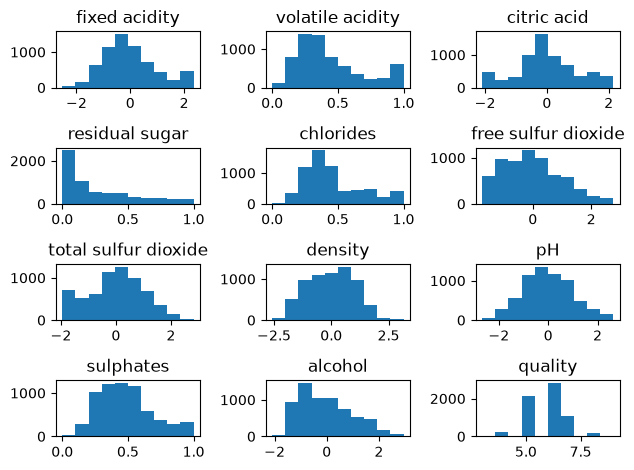

In [353]:
df_es.hist(grid = False)
plt.tight_layout()
plt.show()

Ahora boxplots con los datos escalados.

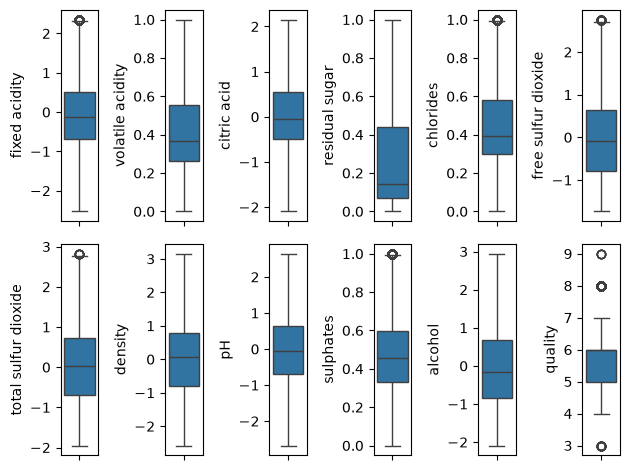

In [354]:
fig, ax = plt.subplots(nrows = 2, ncols = 6)
axes = ax.flatten()
for i, cat in enumerate(df.columns[:-1]):
    sns.boxplot(data = df_es, y = cat, ax = axes[i])

plt.tight_layout()
plt.show()

Habiendo aplicado el método IQR, analizando los valores atípicos (outliers), y escalando los datos según el sesgo de cada variable, hemos conseguido obtener datos más limpios, con distribuciones que harán el entrenamiento del modelo más fácil que con los datos originales. Pues nos hemos deshecho de los outliers, y hemos impuesto rangos en las variables que no difieren en gran medida.

Guardemos los datos limpios.

In [355]:
df_es.to_csv(data_folder + "dataset_cleaned.csv")

# 3

### Nota: 9.32

¿Preparado/a para un nuevo desafío? En esta ocasión, queremos que desarrolles un proyecto de machine learning enfocado en la preparación y transformación de datos utilizando técnicas de codificación de variables categóricas. Trabajarás con el dataset proporcionado dataset.csv y aplicarás diferentes métodos de codificación, como get_dummies de pandas, OneHotEncoder y LabelEncoder de scikit-learn, para preparar los datos para futuros análisis y modelado.

In [356]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

data_folder = "../media/1_lab3/3/"
data_file = "dataset.csv"
seed = 1234

In [357]:
df = pd.read_csv(data_folder + data_file)
df.head()

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
3,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
4,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K


In [358]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32560 entries, 0 to 32559
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   39              32560 non-null  int64
 1    State-gov      32560 non-null  str  
 2    77516          32560 non-null  int64
 3    Bachelors      32560 non-null  str  
 4    13             32560 non-null  int64
 5    Never-married  32560 non-null  str  
 6    Adm-clerical   32560 non-null  str  
 7    Not-in-family  32560 non-null  str  
 8    White          32560 non-null  str  
 9    Male           32560 non-null  str  
 10   2174           32560 non-null  int64
 11   0              32560 non-null  int64
 12   40             32560 non-null  int64
 13   United-States  32560 non-null  str  
 14   <=50K          32560 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


Vemos que es un set de datos con datos personales, en el que no hay nombres de las columnas. Cada fila es una persona, y las columnas son distintos datos descriptivos, los cuales comentamos a continuación en base a la primera fila de los datos:

- 39: Edad
- State_gov: Indica el tipo de administración para la que trabaja la persona.
- Bachelors: Nivel de estudios alcanzado.
- Never-married: Estado civil.
- Adm-clerical: Tipo de oficio.
- Not-in-Family: Puesto relativo en la familia.
- White: Etnia.
- Male: Sexo.
- United-States: País
- <=50K: Sueldo mayor o menor a 50k (entendemos que en la divisa de origen) anuales

El resto de columnas no serán sujetas a interpretaciones, y como son numéricas, se nombrarán como tal.

Es por esto que vamos a definir los siguientes nombres de columnas:

- Edad
- Administración
- Estudios
- Estado Civil
- Oficio
- Puesto Familia
- Etnia
- Sexo
- País
- Rango Sueldo

In [359]:
nombres = ["Edad", "Administrión", "num1", "Estudios", "num2", "Estado Civil", "Oficio", "Puesto Familia", "Etnia", "Sexo", "num3", "num4", "num5", "País", "Rango Sueldo"]
df = pd.read_csv(filepath_or_buffer = data_folder + data_file, names = nombres)
df.head()

,Edad,Administrión,num1,Estudios,num2,Estado Civil,Oficio,Puesto Familia,Etnia,Sexo,num3,num4,num5,País,Rango Sueldo
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Veamos las variables categóricas que hay.

In [360]:
categorical_stats = df.describe(include = "O")
numerical_stats = df.describe(include = np.number)
categorical_cols = categorical_stats.columns
numerical_cols = numerical_stats.columns
df[categorical_cols].head()

/tmp/ipykernel_30584/2339710681.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_stats = df.describe(include = "O")


,Administrión,Estudios,Estado Civil,Oficio,Puesto Familia,Etnia,Sexo,País,Rango Sueldo
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K


In [361]:
categorical_stats.T

,count,unique,top,freq
Administrión,32561,9,Private,22696
Estudios,32561,16,HS-grad,10501
Estado Civil,32561,7,Married-civ-spouse,14976
Oficio,32561,15,Prof-specialty,4140
Puesto Familia,32561,6,Husband,13193
Etnia,32561,5,White,27816
Sexo,32561,2,Male,21790
País,32561,42,United-States,29170
Rango Sueldo,32561,2,<=50K,24720


Veamos los valores únicos de cada columna.

In [362]:
for col in categorical_cols:
    print(f"Valores únicos de la columna {col}")
    print(df[col].unique())
    print("\n")

Valores únicos de la columna Administrión
<StringArray>
[       ' State-gov', ' Self-emp-not-inc',          ' Private',
      ' Federal-gov',        ' Local-gov',                ' ?',
     ' Self-emp-inc',      ' Without-pay',     ' Never-worked']
Length: 9, dtype: str


Valores únicos de la columna Estudios
<StringArray>
[   ' Bachelors',      ' HS-grad',         ' 11th',      ' Masters',
          ' 9th', ' Some-college',   ' Assoc-acdm',    ' Assoc-voc',
      ' 7th-8th',    ' Doctorate',  ' Prof-school',      ' 5th-6th',
         ' 10th',      ' 1st-4th',    ' Preschool',         ' 12th']
Length: 16, dtype: str


Valores únicos de la columna Estado Civil
<StringArray>
[        ' Never-married',    ' Married-civ-spouse',              ' Divorced',
 ' Married-spouse-absent',             ' Separated',     ' Married-AF-spouse',
               ' Widowed']
Length: 7, dtype: str


Valores únicos de la columna Oficio
<StringArray>
[     ' Adm-clerical',   ' Exec-managerial', ' Handlers-clea

Veamos histogramas con la distribución de las variables.

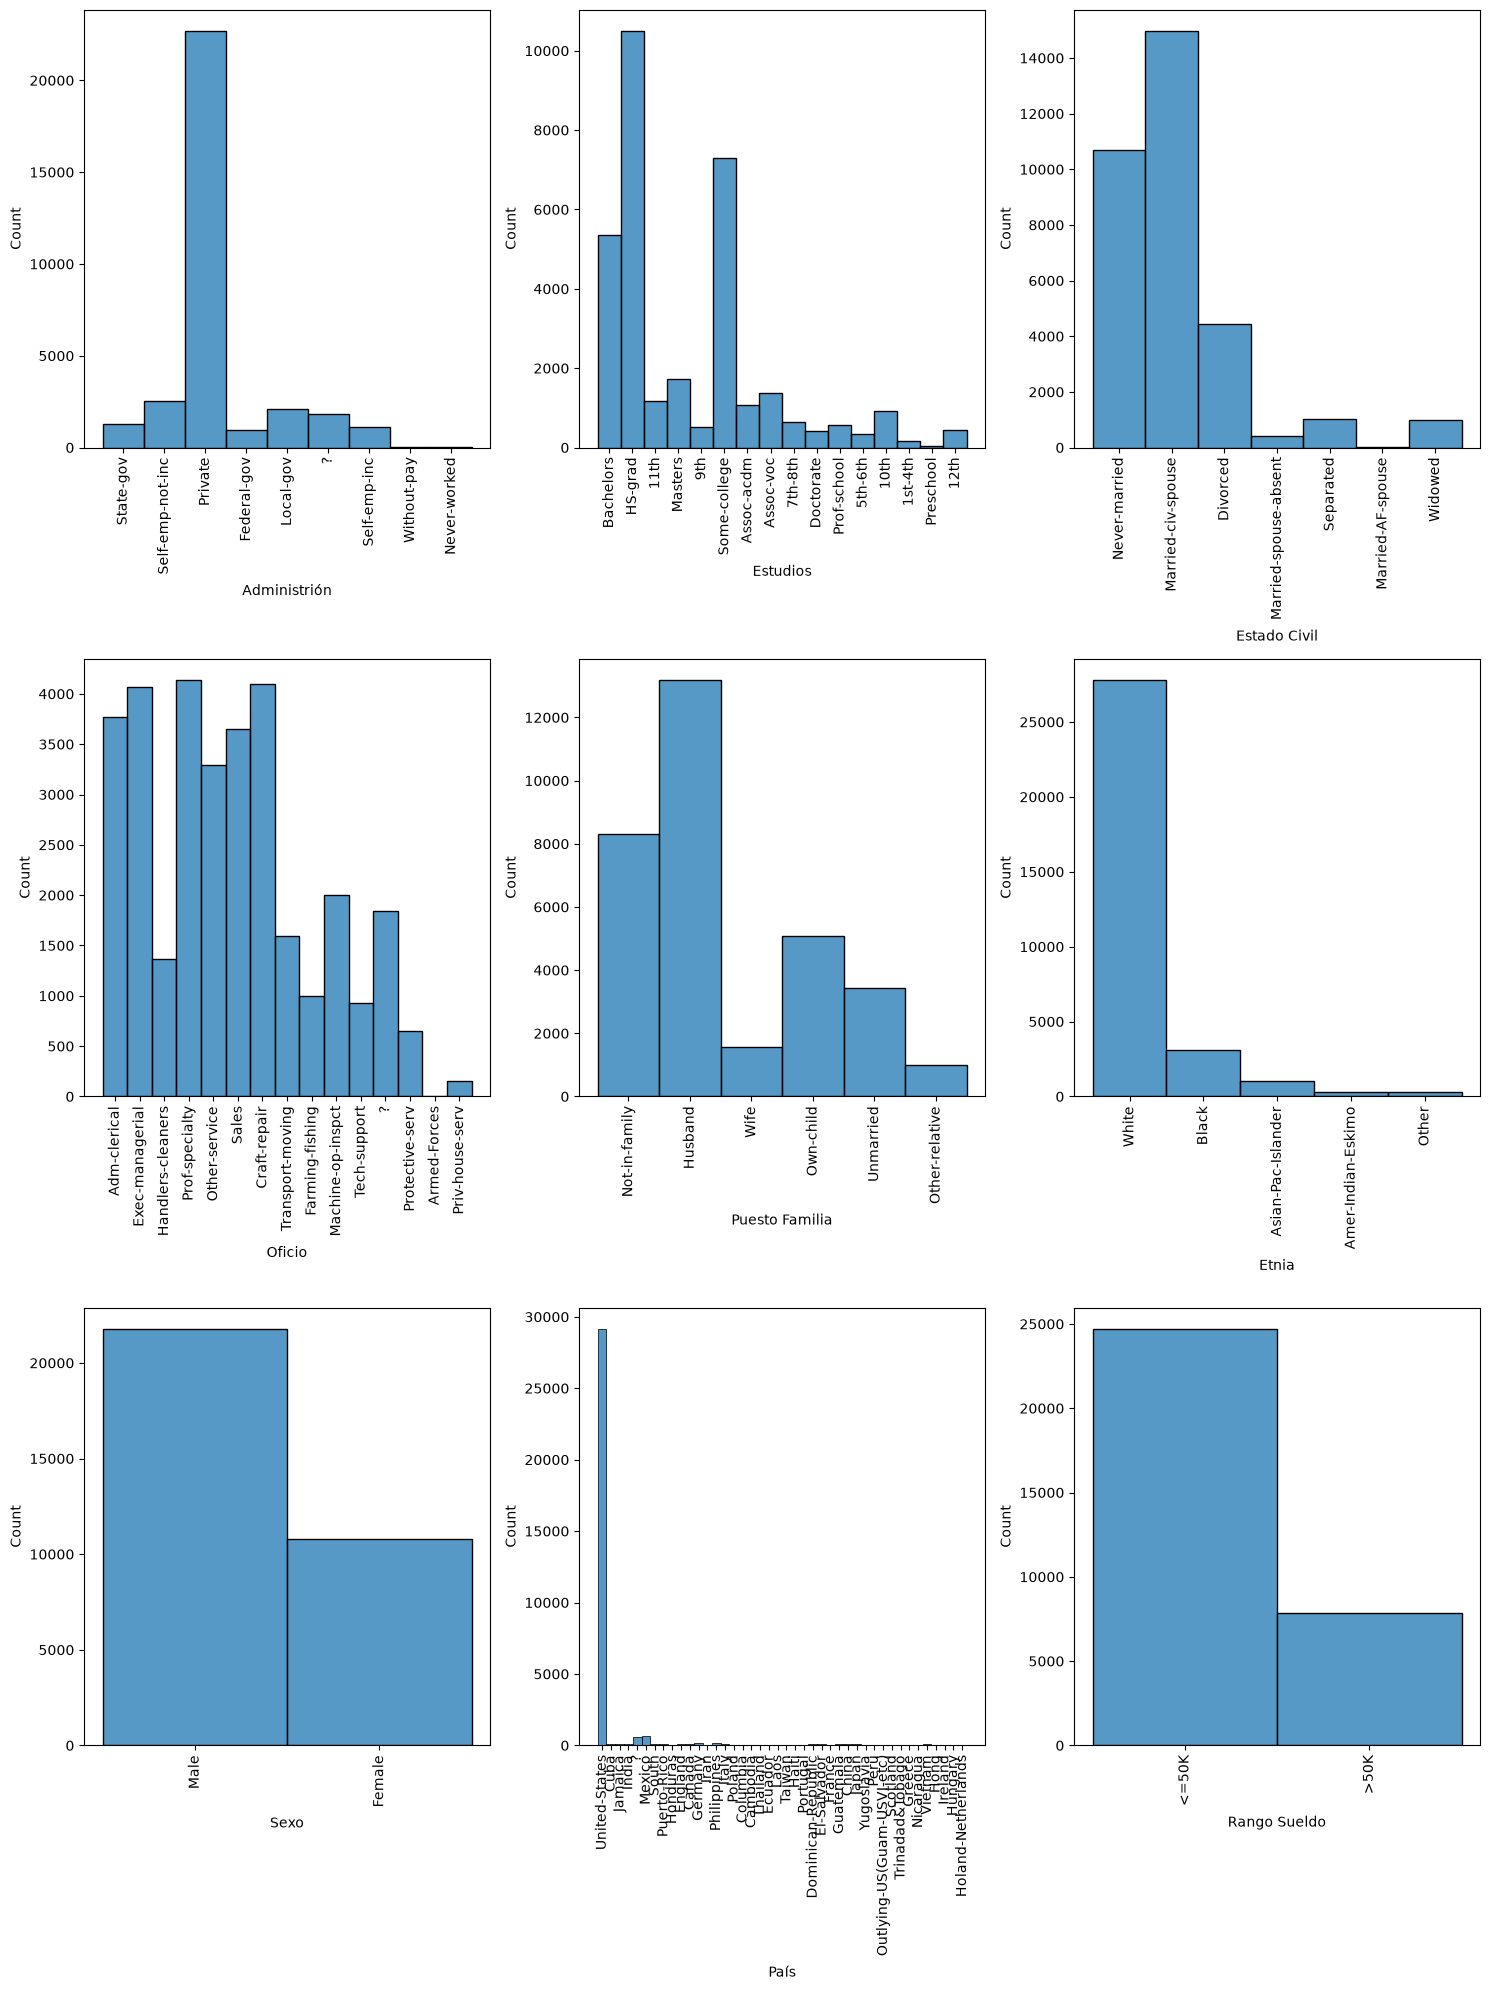

In [363]:
# Veamos cuantas categorías numéricas hay
len(categorical_cols)

# Como son 9, podemos hacer un grid de 3x3
fig, axes = plt.subplots(nrows = 3, ncols = 3)
ax = axes.flatten()
fig.set_figheight(20)
fig.set_figwidth(15)

for idx, col in enumerate(categorical_cols):
    sns.histplot(data = df, x = col, ax = ax[idx])
    ax[idx].tick_params(axis = "x", labelrotation = 90)

plt.tight_layout()
plt.show()


Predominantemente los datos provienen de gente de Estados Unidos, destacan la gente de sexo masculino, la blanca, maridos, con estudios de instituto y trabajadores del sector privado.

Veamos ahora las numéricas.

In [364]:
numerical_stats.T

,count,mean,std,min,25%,50%,75%,max
Edad,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
num1,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
num2,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
num3,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
num4,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
num5,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


Son 6 columnas, hagamos también un histograma.

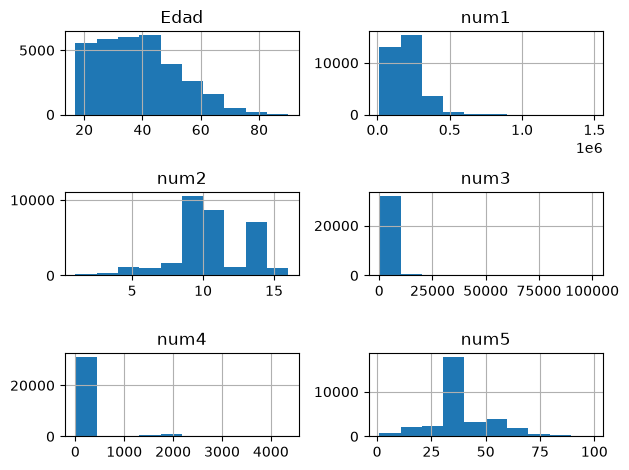

In [365]:
df[numerical_cols].hist()
plt.tight_layout()
plt.show()

Las variables num1, nu,3 y num4 parecen tener una distribución asimétrica, con cola hacia la derecha, lo que lleva a cierto sesgo en las mismas, esto se ve además porque en estas variables la media difiere significativamente de la mediana.

Hagamos también un boxplot.

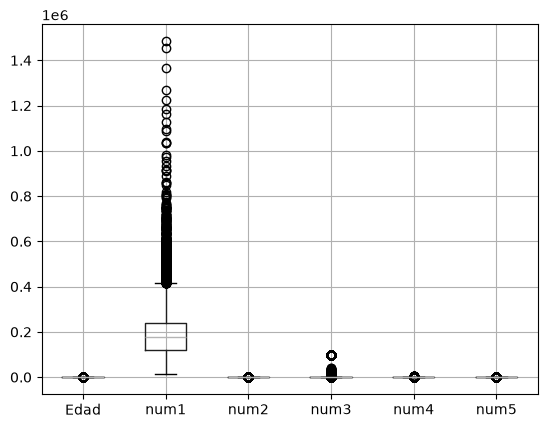

In [366]:
df[numerical_cols].boxplot()
plt.show()

Vemos que la columna *num1* tiene muchos outliers. Como este entrenamiento no va de eso, no se va a manipular, pero se podría limpiar usando el método IQR.

## Transformaciones

Apliquemos algunas transformaciones a las variables categóricas, y veamos cuáles son las mejores opciones para cada una.

### Codificación con *get_dummies*

In [367]:
df_pd_dummies = pd.get_dummies(data = df[categorical_cols]).astype(int)
df_pd_dummies.head()

,Administrión_ ?,Administrión_ Federal-gov,Administrión_ Local-gov,Administrión_ Never-worked,Administrión_ Private,Administrión_ Self-emp-inc,Administrión_ Self-emp-not-inc,Administrión_ State-gov,Administrión_ Without-pay,Estudios_ 10th,...,País_ Scotland,País_ South,País_ Taiwan,País_ Thailand,País_ Trinadad&Tobago,País_ United-States,País_ Vietnam,País_ Yugoslavia,Rango Sueldo_ <=50K,Rango Sueldo_ >50K
0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,1,0
1,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
2,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
3,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
4,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


Este método convierte una columna con $N$ valores únicos a $N$ columnas cuyos valores posibles son 0 y 1 (El propio método genera booleanos, pero con astype lo pasamos a números enteros para que un modelo pueda leerlo). El principal problema de este método es que el número de columnas aumenta en una gran cantidad:

In [368]:
len(df_pd_dummies.columns)

104

Por lo que esta codificación solo sería útil para variables que tienen pocas categorías (2 o 3 por ejemplo).

In [369]:
categorical_stats.T.unique

Administrión       9
Estudios          16
Estado Civil       7
Oficio            15
Puesto Familia     6
Etnia              5
Sexo               2
País              42
Rango Sueldo       2
Name: unique, dtype: object

En este caso, sería una codificación útil para las columnas *Sexo* y *Rango sueldo*. Esta codificación es de tipo One Hot, y es la que viene por defecto al trabajar con DataFrames de pandas. Veremos a continuación la codificación One Hot que provee la librería scikit-learn.

### Codificación con *OneHotEncoder*

In [370]:
oh_encoder = sk.preprocessing.OneHotEncoder(sparse_output = False).set_output(transform = "pandas")

df_onehot = oh_encoder.fit_transform(df[categorical_cols])
df_onehot.head()

,Administrión_ ?,Administrión_ Federal-gov,Administrión_ Local-gov,Administrión_ Never-worked,Administrión_ Private,Administrión_ Self-emp-inc,Administrión_ Self-emp-not-inc,Administrión_ State-gov,Administrión_ Without-pay,Estudios_ 10th,...,País_ Scotland,País_ South,País_ Taiwan,País_ Thailand,País_ Trinadad&Tobago,País_ United-States,País_ Vietnam,País_ Yugoslavia,Rango Sueldo_ <=50K,Rango Sueldo_ >50K
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [371]:
df_pd_dummies[df_onehot != df_pd_dummies].sum().sum()

np.float64(0.0)

In [372]:
len(df_onehot.columns)

104

Podemos ver que en efecto nos devuelve un DataFrame idéntico al método *get_dummies*, pero en este caso codificado con otra librería. Esta codificación puede ser útil cuando se va alimentar un pipeline de sklearn.

### Codificación con *LabelEncoder*

In [373]:
lab_encoder = sk.preprocessing.LabelEncoder()

df_label = df[categorical_cols].apply(lab_encoder.fit_transform)
df_label.head()

,Administrión,Estudios,Estado Civil,Oficio,Puesto Familia,Etnia,Sexo,País,Rango Sueldo
0,7,9,4,1,1,4,1,39,0
1,6,9,2,4,0,4,1,39,0
2,4,11,0,6,1,4,1,39,0
3,4,1,2,6,0,2,1,39,0
4,4,9,2,10,5,2,0,5,0


El *LabelEncoder* le asigna un número a cada una de las categorías, de forma que una columna categórica de $N$ categorías, se convierte en una columna numérica de números enteros del 0 al $N - 1$. Esto sería una mejor opción que el one hot encoding, pero seguiría sin ser suficiente, ya que induce a un orden artificial (y aleatorio a no ser que existe una prioridad en las categorías, y se haya ordenado según esta), que puede dar lugar a fallos en el modelo. Pasamos de 104 columnas, a las mismas 9 columnas que teníamos al principio.

# Comparación de métodos (necesario para este entrenamiento)

Vamos a comparar los distintos métodos de codificación que hemos visto:

## Codificación One Hot

La codificación One Hot consiste en convertir una variable categórica, en varias variables categóricas con valores 0 y 1. 

### Codificación con *get_dummies*

La codificación One Hot con la función get_dummies es bastante sencilla, viene integrada directamente en pandas, y no hay que fijar parámetros concretos, ni hay mayor problema en su aplicación. Solo necesita como parámetro el DataFrame con variables categóricas a codificar, aunque hay que tener en cuenta que esta función devuelve el DataFrame con booleanos, por lo que hay que cambiar de dtype manualmente. Como vimos es un método que hace que aumente de sobre manera el número de columnas del DataFrame, por lo que solo sería útil para las columnas *Sexo* y *Rango Sueldo*

### Codificación con *OneHotEncoder*

En este caso se usa el codificador que viene directamente de la librería scikit learn. Primero hay que definir el codificador, ajustando ciertos parámetros para que, a la hora de transformar el DataFrame, devuelva un Array denso que a su vez pueda leer pandas. El resultado es directamente numérico, y haciendo la comparativa en el código hemos visto que en efecto es el mismo DataFrame que el obtenido con *get_dummies*. Esta codificación resultaría más útil en el caso de que se quisiese construir una pipeline de scikit learn para alimentar un modelo del mismo.

## Codidicación de etiquetas (Label Encoding)

El Label Encoding transforma una variable categórica, en una única variable numérica, asignando a cada categoría un número entero.

### Codificación con *LabelEncoder*

Este codificador es más fácil que usar, solo se define el codificador, sin ningún parámetro, y aplicar el método de fit_transform al DataFrame ya lo codifica. En este caso, podría aplicarse al resto de columnas categóricas en las que no se usó la codificación One Hot, debido al número de categorías únicas que estas tienen. Hay que tener en cuenta que tampoco es aconsejable usarlo cuando el número de categorías de la variable es excesivo. Otro factor importante es que induce a un orden artificial (y aleatorio a no ser que existe una prioridad en las categorías, y se haya ordenado según esta) a las categorÍas de la variable, que puede dar lugar a fallos en el modelo y problemas de intepretabilidad.
